In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    KFold
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import (
    KNeighborsClassifier,
    KNeighborsRegressor
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)



In [2]:

from sklearn.datasets import make_classification

X_cls, y_cls = make_classification(
    n_samples=5000,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=2,
    weights=[0.65, 0.35],
    class_sep=1.2,
    random_state=42
)

print("Features shape:", X_cls.shape)
print("Target shape:", y_cls.shape)


Features shape: (5000, 6)
Target shape: (5000,)


In [3]:

feature_names = [
    "Annual_Income",
    "Credit_Score",
    "Monthly_Transactions",
    "Account_Balance",
    "Customer_Age",
    "Transaction_Value"
]

df_cls = pd.DataFrame(X_cls, columns=feature_names)
df_cls["Customer_Class"] = y_cls

df_cls.head()


,Annual_Income,Credit_Score,Monthly_Transactions,Account_Balance,Customer_Age,Transaction_Value,Customer_Class
0,-0.392663,1.867223,0.178499,-1.027744,-0.057535,-1.654566,1
1,1.099432,-1.330962,1.183211,-1.083653,-1.504676,0.267640,0
2,-1.440893,1.611635,0.768394,-1.160156,2.719280,0.013742,0
3,0.593775,-2.810231,-1.329400,-0.570548,0.138187,-1.784447,0
4,0.227326,-1.777856,-1.596111,1.110286,0.271825,0.750920,1


In [4]:

print("Dataset Shape:", df_cls.shape)

print("\nDataset Information:")
df_cls.info()

print("\nMissing Values:")
print(df_cls.isnull().sum())

print("\nStatistical Summary:")
display(df_cls.describe())

print("\nClass Distribution:")
print(df_cls["Customer_Class"].value_counts())

print("\nClass Distribution (%):")
print(
    df_cls["Customer_Class"]
    .value_counts(normalize=True)
    .mul(100)
)


Dataset Shape: (5000, 7)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Annual_Income         5000 non-null   float64
 1   Credit_Score          5000 non-null   float64
 2   Monthly_Transactions  5000 non-null   float64
 3   Account_Balance       5000 non-null   float64
 4   Customer_Age          5000 non-null   float64
 5   Transaction_Value     5000 non-null   float64
 6   Customer_Class        5000 non-null   int64  
dtypes: float64(6), int64(1)
memory usage: 273.6 KB

Missing Values:
Annual_Income           0
Credit_Score            0
Monthly_Transactions    0
Account_Balance         0
Customer_Age            0
Transaction_Value       0
Customer_Class          0
dtype: int64

Statistical Summary:


,Annual_Income,Credit_Score,Monthly_Transactions,Account_Balance,Customer_Age,Transaction_Value,Customer_Class
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,0.043133,-0.002313,0.021755,-0.774337,0.006530,-0.789644,0.35460
std,0.925883,1.647541,0.999434,1.423186,1.703606,1.564185,0.47844
min,-2.905712,-6.139354,-4.478522,-6.221575,-5.513798,-6.325572,0.00000
25%,-0.696864,-1.287770,-0.655644,-1.733212,-1.241835,-1.816294,0.00000
50%,0.053465,0.177470,0.028680,-0.943422,-0.004632,-0.905872,0.00000
75%,0.824972,1.243961,0.727685,0.190540,1.292140,0.214379,1.00000
max,3.457915,6.402747,3.326781,3.744839,5.733238,4.769157,1.00000



Class Distribution:
Customer_Class
0    3227
1    1773
Name: count, dtype: int64

Class Distribution (%):
Customer_Class
0    64.54
1    35.46
Name: proportion, dtype: float64


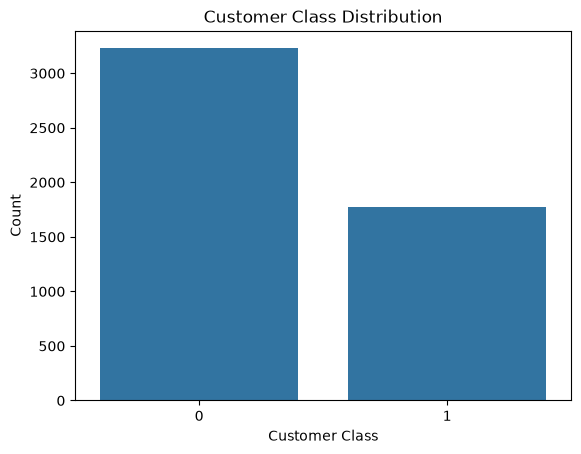

In [5]:

sns.countplot(
    data=df_cls,
    x="Customer_Class"
)

plt.title("Customer Class Distribution")
plt.xlabel("Customer Class")
plt.ylabel("Count")
plt.show()


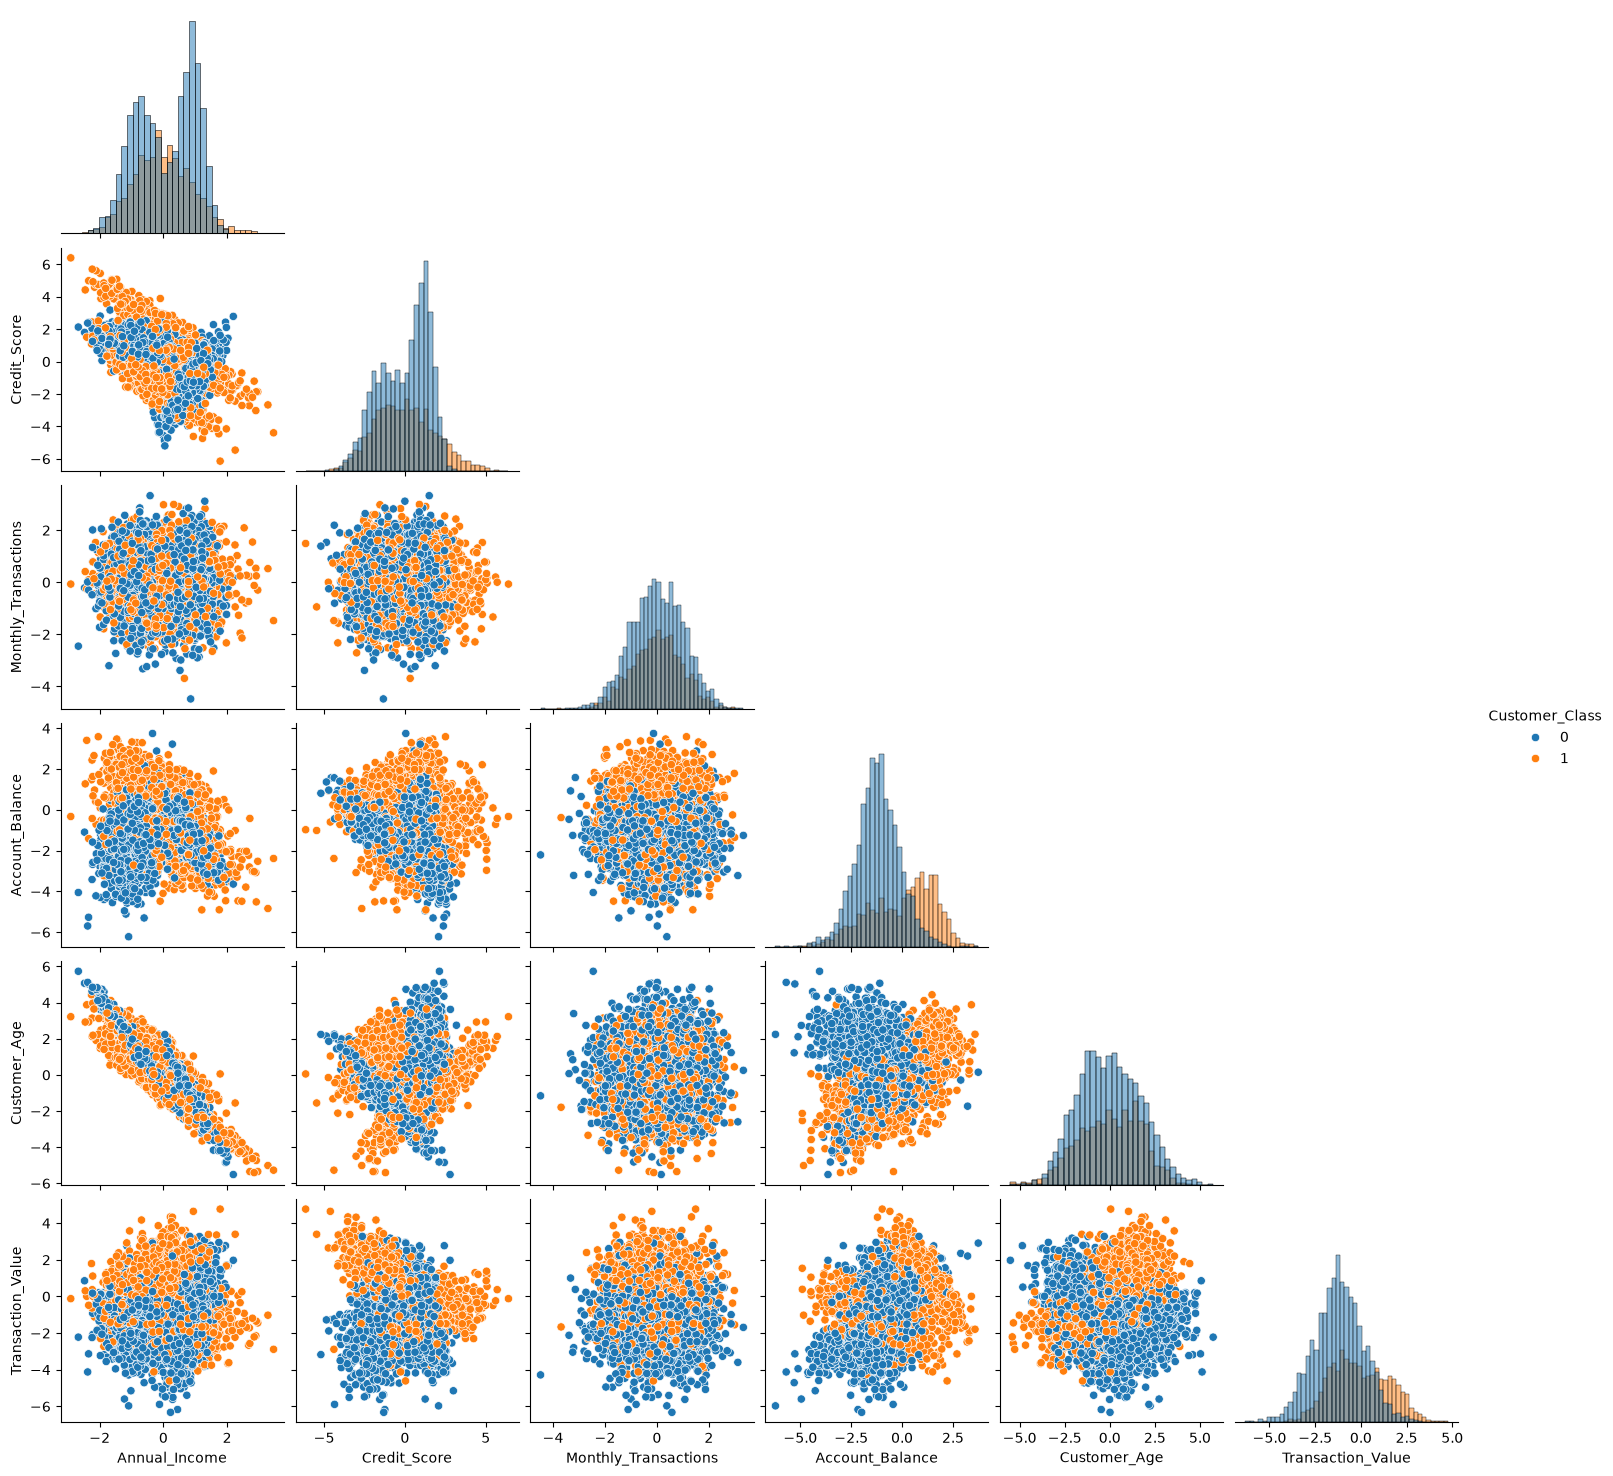

In [6]:

sns.pairplot(
    df_cls,
    vars=feature_names,
    hue="Customer_Class",
    corner=True,
    diag_kind="hist"
)

plt.show()


In [7]:

X = df_cls.drop(columns=["Customer_Class"])
y = df_cls["Customer_Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (5000, 6)
y shape: (5000,)


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (4000, 6)
X_test: (1000, 6)
y_train: (4000,)
y_test: (1000,)


In [10]:

print("Training Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True))


Training Distribution:
Customer_Class
0    0.6455
1    0.3545
Name: proportion, dtype: float64

Testing Distribution:
Customer_Class
0    0.645
1    0.355
Name: proportion, dtype: float64


In [11]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before Scaling:")
display(X_train.describe())

print("\nAfter Scaling:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
).describe())


Before Scaling:


,Annual_Income,Credit_Score,Monthly_Transactions,Account_Balance,Customer_Age,Transaction_Value
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,0.047988,-0.005640,0.021469,-0.770413,-0.004552,-0.796588
std,0.927520,1.651065,1.005954,1.422703,1.707151,1.567800
min,-2.905712,-6.139354,-3.688534,-6.221575,-5.513798,-6.325572
25%,-0.696864,-1.295754,-0.670706,-1.733212,-1.260923,-1.831952
50%,0.069613,0.177390,0.032108,-0.937387,-0.012816,-0.912443
75%,0.832287,1.242374,0.731149,0.168757,1.268028,0.221375
max,3.457915,6.402747,3.326781,3.744839,5.733238,4.769157



After Scaling:


,Annual_Income,Credit_Score,Monthly_Transactions,Account_Balance,Customer_Age,Transaction_Value
count,4.000000e+03,4.000000e+03,4.000000e+03,4.000000e+03,4.000000e+03,4.000000e+03
mean,-1.332268e-17,1.421085e-17,-6.661338e-18,-6.394885e-17,1.687539e-17,4.796163e-17
std,1.000125e+00,1.000125e+00,1.000125e+00,1.000125e+00,1.000125e+00,1.000125e+00
min,-3.184911e+00,-3.715469e+00,-3.688505e+00,-3.832033e+00,-3.227561e+00,-3.527029e+00
25%,-8.031571e-01,-7.814803e-01,-6.881634e-01,-6.768241e-01,-7.360381e-01,-6.604756e-01
50%,2.331809e-02,1.108698e-01,1.057733e-02,-1.173784e-01,-4.841676e-03,-7.390623e-02
75%,8.456931e-01,7.559785e-01,7.055681e-01,6.602135e-01,7.455337e-01,6.493753e-01
max,3.676852e+00,3.881850e+00,3.286159e+00,3.174112e+00,3.361453e+00,3.550480e+00


In [12]:


knn_brute_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        algorithm="brute"
    ))
])

knn_brute_clf


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value 

In [23]:

param_grid = [
    {
        "knn__metric": ["euclidean", "manhattan"],
        "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "knn__weights": ["uniform", "distance"]
    },
    {
        "knn__metric": ["minkowski"],
        "knn__p": [1, 2],
        "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "knn__weights": ["uniform", "distance"]
    }
]
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_brute_clf = GridSearchCV(
    estimator=knn_brute_clf,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

start_time = time.perf_counter()

grid_search_brute_clf.fit(X_train, y_train)

fit_time_brute_clf = time.perf_counter() - start_time

print("Best Parameters:")
print(grid_search_brute_clf.best_params_)

print("\nBest CV Accuracy:")
print(grid_search_brute_clf.best_score_)

print("\nGrid Search Time:")
print(f"{fit_time_brute_clf:.2f} seconds")


Fitting 5 folds for each of 56 candidates, totalling 280 fits
Best Parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}

Best CV Accuracy:
0.93225

Grid Search Time:
5.84 seconds


In [24]:

best_brute_clf = grid_search_brute_clf.best_estimator_

start_time = time.perf_counter()

y_pred_brute_clf = best_brute_clf.predict(X_test)

prediction_time_brute_clf = time.perf_counter() - start_time

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_brute_clf))

print("Precision:",
      precision_score(y_test, y_pred_brute_clf))

print("Recall:",
      recall_score(y_test, y_pred_brute_clf))

print("F1 Score:",
      f1_score(y_test, y_pred_brute_clf))

print("Prediction Time:",
      f"{prediction_time_brute_clf:.6f} seconds")


Test Accuracy: 0.928
Precision: 0.924924924924925
Recall: 0.8676056338028169
F1 Score: 0.8953488372093024
Prediction Time: 0.012905 seconds


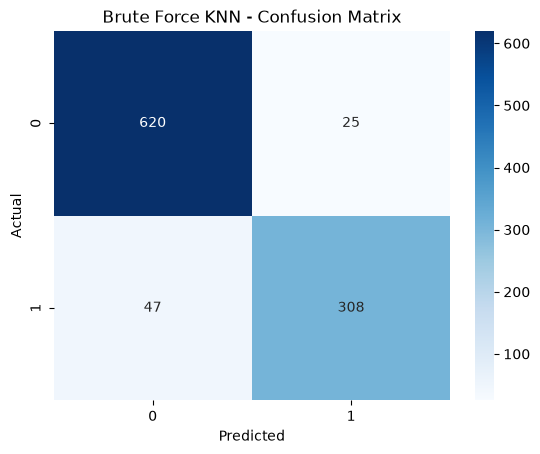

              precision    recall  f1-score   support

           0       0.93      0.96      0.95       645
           1       0.92      0.87      0.90       355

    accuracy                           0.93      1000
   macro avg       0.93      0.91      0.92      1000
weighted avg       0.93      0.93      0.93      1000



In [25]:

cm = confusion_matrix(y_test, y_pred_brute_clf)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Brute Force KNN - Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred_brute_clf))


In [26]:

knn_kdtree_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        algorithm="kd_tree"
    ))
])

knn_kdtree_clf


param_grid_kdtree = [
    {
        "knn__metric": ["euclidean", "manhattan"],
        "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "knn__weights": ["uniform", "distance"]
    },
    {
        "knn__metric": ["minkowski"],
        "knn__p": [1, 2],
        "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "knn__weights": ["uniform", "distance"]
    }
]

grid_search_kdtree_clf = GridSearchCV(
    estimator=knn_kdtree_clf,
    param_grid=param_grid_kdtree,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

start_time = time.perf_counter()

grid_search_kdtree_clf.fit(X_train, y_train)

fit_time_kdtree_clf = time.perf_counter() - start_time

print("Best Parameters:")
print(grid_search_kdtree_clf.best_params_)

print("\nBest CV Accuracy:")
print(grid_search_kdtree_clf.best_score_)

print("\nGrid Search Time:")
print(f"{fit_time_kdtree_clf:.2f} seconds")


Fitting 5 folds for each of 56 candidates, totalling 280 fits
Best Parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}

Best CV Accuracy:
0.93225

Grid Search Time:
0.86 seconds


In [27]:

best_kdtree_clf = grid_search_kdtree_clf.best_estimator_

start_time = time.perf_counter()

y_pred_kdtree_clf = best_kdtree_clf.predict(X_test)

prediction_time_kdtree_clf = time.perf_counter() - start_time

print("Accuracy:",
      accuracy_score(y_test, y_pred_kdtree_clf))

print("Precision:",
      precision_score(y_test, y_pred_kdtree_clf))

print("Recall:",
      recall_score(y_test, y_pred_kdtree_clf))

print("F1 Score:",
      f1_score(y_test, y_pred_kdtree_clf))

print("Prediction Time:",
      f"{prediction_time_kdtree_clf:.6f} seconds")


Accuracy: 0.928
Precision: 0.924924924924925
Recall: 0.8676056338028169
F1 Score: 0.8953488372093024
Prediction Time: 0.009513 seconds


In [28]:

knn_balltree_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        algorithm="ball_tree"
    ))
])

knn_balltree_clf


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'ball_tree'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal va

In [29]:
param_grid_balltree = [
    {
        "knn__metric": ["euclidean", "manhattan"],
        "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "knn__weights": ["uniform", "distance"]
    },
    {
        "knn__metric": ["minkowski"],
        "knn__p": [1, 2],
        "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "knn__weights": ["uniform", "distance"]
    }
]

In [30]:

grid_search_balltree_clf = GridSearchCV(
    estimator=knn_balltree_clf,
    param_grid=param_grid_balltree,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

start_time = time.perf_counter()

grid_search_balltree_clf.fit(X_train, y_train)

fit_time_balltree_clf = time.perf_counter() - start_time

print("Best Parameters:")
print(grid_search_balltree_clf.best_params_)

print("\nBest CV Accuracy:")
print(grid_search_balltree_clf.best_score_)

print("\nGrid Search Time:")
print(f"{fit_time_balltree_clf:.2f} seconds")


Fitting 5 folds for each of 56 candidates, totalling 280 fits
Best Parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}

Best CV Accuracy:
0.93225

Grid Search Time:
1.29 seconds


In [31]:

best_balltree_clf = grid_search_balltree_clf.best_estimator_

start_time = time.perf_counter()

y_pred_balltree_clf = best_balltree_clf.predict(X_test)

prediction_time_balltree_clf = time.perf_counter() - start_time

print("Accuracy:",
      accuracy_score(y_test, y_pred_balltree_clf))

print("Precision:",
      precision_score(y_test, y_pred_balltree_clf))

print("Recall:",
      recall_score(y_test, y_pred_balltree_clf))

print("F1 Score:",
      f1_score(y_test, y_pred_balltree_clf))

print("Prediction Time:",
      f"{prediction_time_balltree_clf:.6f} seconds")


Accuracy: 0.928
Precision: 0.924924924924925
Recall: 0.8676056338028169
F1 Score: 0.8953488372093024
Prediction Time: 0.047954 seconds


In [32]:

comparison_df = pd.DataFrame({
    "Algorithm": [
        "Brute Force",
        "KD Tree",
        "Ball Tree"
    ],
    "Best CV Accuracy": [
        grid_search_brute_clf.best_score_,
        grid_search_kdtree_clf.best_score_,
        grid_search_balltree_clf.best_score_
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred_brute_clf),
        accuracy_score(y_test, y_pred_kdtree_clf),
        accuracy_score(y_test, y_pred_balltree_clf)
    ],
    "Test F1 Score": [
        f1_score(y_test, y_pred_brute_clf),
        f1_score(y_test, y_pred_kdtree_clf),
        f1_score(y_test, y_pred_balltree_clf)
    ],
    "Grid Search Time (sec)": [
        fit_time_brute_clf,
        fit_time_kdtree_clf,
        fit_time_balltree_clf
    ],
    "Prediction Time (sec)": [
        prediction_time_brute_clf,
        prediction_time_kdtree_clf,
        prediction_time_balltree_clf
    ]
})

comparison_df


,Algorithm,Best CV Accuracy,Test Accuracy,Test F1 Score,Grid Search Time (sec),Prediction Time (sec)
0,Brute Force,0.93225,0.928,0.895349,5.844673,0.012905
1,KD Tree,0.93225,0.928,0.895349,0.857417,0.009513
2,Ball Tree,0.93225,0.928,0.895349,1.289331,0.047954
